# Perfiles y pronóstico de PM2.5 en Pekín: revisión del análisis

Este notebook repite el análisis de `Analisis_PM25.ipynb` e incorpora los cambios propuestos en la revisión:

1. **Agrupamiento por forma.** Estandarizamos cada día antes de k-means para agrupar perfiles por su forma y estudiamos el nivel por separado. Elegimos `k` con *silhouette* y con el método del codo.
2. **Sesgo de los días descartados.** Comprobamos si los días incompletos tienen un PM2.5 distinto al de los días completos.
3. **Regresión.** Guardamos los modelos y sus predicciones por nombre y probamos `log1p(Iws)` y su interacción con la dirección del viento.
4. **Dos tareas distintas.** Separamos la estimación con la meteorología de la misma hora del pronóstico a una hora. Para el pronóstico añadimos una regresión con PM2.5 retardado y meteorología de la hora anterior.
5. **Ciclo diario en el ARIMA.** Probamos un SARIMA con periodo de 24 horas y un ARIMA con términos de Fourier diarios y meteorología.
6. **Selección sin fuga de información.** La ACF y la PACF se calculan solo con 2010–2012; 2013 queda para validación y 2014 para la evaluación final.

Se ejecuta desde la raíz del repositorio. El ajuste del SARIMA tarda unos minutos.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import adjusted_rand_score, mean_absolute_error, silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

ZONA = "Asia/Shanghai"
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
         "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
SEMILLA = 42

## 1. Preprocesamiento

Mismas decisiones que en el análisis original, sin posiciones fijadas a mano:

- La fecha y hora se construye en hora local de Pekín.
- Si el punto de rocío supera la temperatura, se iguala a la temperatura (el cambio mínimo que cumple la regla).
- La serie empieza a las 00:00 del primer día con alguna medición de PM2.5, en lugar de usar `iloc[24:]`.

In [2]:
datos = pd.read_csv(Path("data") / "dataset.csv", na_values=["NA"])
datos["fecha_hora"] = (
    pd.to_datetime(datos[["year", "month", "day", "hour"]], errors="raise")
    .dt.tz_localize(ZONA)
)
datos = datos.sort_values("fecha_hora").reset_index(drop=True)

rocio_superior = datos["DEWP"] > datos["TEMP"]
display(datos.loc[rocio_superior, ["fecha_hora", "TEMP", "DEWP"]])
datos.loc[rocio_superior, "DEWP"] = datos.loc[rocio_superior, "TEMP"]

primera_medicion = datos.loc[datos["pm2.5"].first_valid_index(), "fecha_hora"]
inicio_serie = primera_medicion.normalize()

datos_analisis = (
    datos.loc[datos["fecha_hora"] >= inicio_serie]
    .drop(columns="No")
    .reset_index(drop=True)
)
datos_analisis["dia"] = datos_analisis["fecha_hora"].dt.date

print(f"Inicio de la serie: {inicio_serie}")
print(f"Horas: {len(datos_analisis):,} · sin PM2.5: {datos_analisis['pm2.5'].isna().sum():,}")

,fecha_hora,TEMP,DEWP
6727,2010-10-08 07:00:00+08:00,12.0,13


Inicio de la serie: 2010-01-02 00:00:00+08:00
Horas: 43,800 · sin PM2.5: 2,043


## 2. Perfiles diarios por forma

### 2.1 Representación PAA y estandarización

Cada día completo se resume en seis medias de cuatro horas (PAA). Después restamos a cada día su media y dividimos por su desviación típica. Así, dos días con la misma forma pero distinto nivel quedan juntos. El nivel del día (su media) se guarda aparte.

In [3]:
pm25_por_dia = (
    datos_analisis.pivot(index="dia", columns="hour", values="pm2.5")
    .reindex(columns=range(24))
)
dias_completos = pm25_por_dia.dropna()

franjas = [f"{h:02d}–{h + 3:02d}" for h in range(0, 24, 4)]
perfiles_paa = pd.DataFrame(
    {f: dias_completos.loc[:, h:h + 3].mean(axis=1) for f, h in zip(franjas, range(0, 24, 4))}
)

nivel_diario = perfiles_paa.mean(axis=1)
dispersion_diaria = perfiles_paa.std(axis=1)
perfiles_forma = perfiles_paa.sub(nivel_diario, axis=0).div(dispersion_diaria, axis=0)

print(f"Días completos: {len(perfiles_paa):,} de {len(pm25_por_dia):,}")
print(f"Días con las seis franjas iguales (sin forma definida): {(dispersion_diaria == 0).sum()}")
display(perfiles_forma.head().round(2))

Días completos: 1,571 de 1,825
Días con las seis franjas iguales (sin forma definida): 0


,00–03,04–07,08–11,12–15,16–19,20–23
dia,,,,,,
2010-01-02,0.53,-1.72,-0.64,0.64,0.93,0.26
2010-01-03,-0.92,0.21,0.62,1.58,-0.99,-0.51
2010-01-04,1.98,-0.70,-0.64,-0.23,-0.36,-0.04
2010-01-05,-0.68,-0.76,-0.61,-0.38,0.70,1.72
2010-01-06,0.01,-0.94,-0.76,-0.49,0.40,1.77


### 2.2 Elección del número de grupos

Probamos de 2 a 8 grupos. El *silhouette* mide la separación entre grupos y tiende a favorecer `k = 2`. La inercia (suma de distancias al centroide) siempre baja al añadir grupos; buscamos el punto a partir del cual la mejora se vuelve pequeña (codo).

,silhouette,inercia,mejora_inercia_pct
k,,,
2,0.377,4362.555,NaN
3,0.351,3395.452,22.168
4,0.279,2882.542,15.106
5,0.255,2560.564,11.170
6,0.261,2333.387,8.872
7,0.252,2132.781,8.597
8,0.258,1997.677,6.335


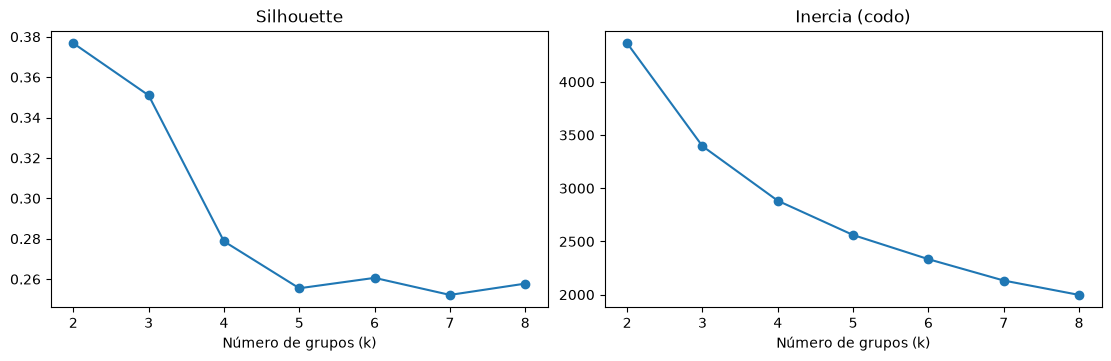

In [4]:
modelos_forma = {}
evaluacion_forma = []

for k in range(2, 9):
    modelo = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(perfiles_forma)
    modelos_forma[k] = modelo
    evaluacion_forma.append({
        "k": k,
        "silhouette": silhouette_score(perfiles_forma, modelo.labels_),
        "inercia": modelo.inertia_,
    })

evaluacion_forma = pd.DataFrame(evaluacion_forma).set_index("k")
evaluacion_forma["mejora_inercia_pct"] = -100 * evaluacion_forma["inercia"].pct_change()
display(evaluacion_forma.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
evaluacion_forma["silhouette"].plot(marker="o", ax=axes[0], title="Silhouette")
evaluacion_forma["inercia"].plot(marker="o", ax=axes[1], title="Inercia (codo)")
for ax in axes:
    ax.set_xlabel("Número de grupos (k)")
plt.show()

El *silhouette* es máximo con **k = 2 (0,377)**, pero con **k = 3 (0,351)** apenas baja; a partir de k = 4 cae a 0,28 o menos. La inercia mejora un **22,2 %** al pasar de 2 a 3 grupos y un 15,1 % de 3 a 4; después, las mejoras se quedan por debajo del 12 %.

Elegimos **k = 3**: la separación es casi la misma que con dos grupos, es el último valor antes de que el *silhouette* empeore claramente y, como se ve a continuación, los tres perfiles se pueden interpretar.

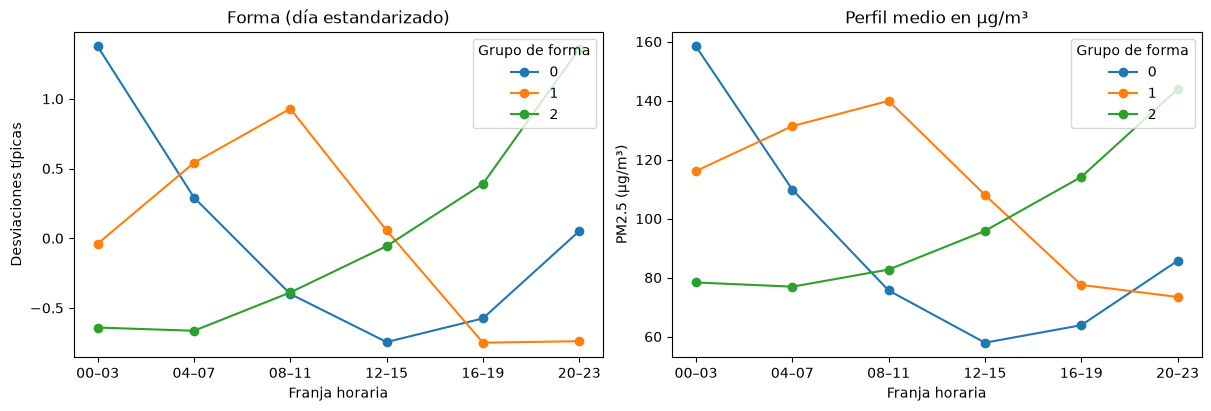

,dias,nivel_mediano,pct_dias
grupo_forma,,,
0,482,69.0,30.7
1,367,92.8,23.4
2,722,76.5,46.0


In [5]:
K_FORMA = 3

modelo_forma = modelos_forma[K_FORMA]
dias_forma = pd.DataFrame({
    "grupo_forma": modelo_forma.labels_,
    "nivel": nivel_diario,
})

centroides = pd.DataFrame(modelo_forma.cluster_centers_, columns=franjas)
nivel_por_forma = perfiles_paa.groupby(dias_forma["grupo_forma"]).mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
centroides.T.plot(marker="o", ax=axes[0])
axes[0].set(title="Forma (día estandarizado)", xlabel="Franja horaria", ylabel="Desviaciones típicas")
nivel_por_forma.T.plot(marker="o", ax=axes[1])
axes[1].set(title="Perfil medio en µg/m³", xlabel="Franja horaria", ylabel="PM2.5 (µg/m³)")
for ax in axes:
    ax.legend(title="Grupo de forma")
plt.show()

display(
    dias_forma.groupby("grupo_forma")
    .agg(dias=("nivel", "size"), nivel_mediano=("nivel", "median"))
    .assign(pct_dias=lambda t: 100 * t["dias"] / t["dias"].sum())
    .round(1)
)

Al quitar el nivel aparecen tres formas distintas. En el análisis original quedaban ocultas porque los dos grupos se diferenciaban sobre todo por su nivel:

- **Grupo 0, limpieza diurna (482 días, 30,7 %).** El máximo está de madrugada, unos 158 µg/m³ de media entre las 00:00 y las 03:59, y la concentración baja hasta un mínimo de 58 µg/m³ entre las 12:00 y las 15:59.
- **Grupo 1, pico de mañana (367 días, 23,4 %).** Sube hasta unos 140 µg/m³ entre las 08:00 y las 11:59 y cae por la tarde hasta unos 75 µg/m³. Es el grupo de nivel mediano más alto (93 µg/m³).
- **Grupo 2, acumulación vespertina (722 días, 46,0 %).** Empieza bajo y sube durante todo el día hasta unos 144 µg/m³ entre las 20:00 y las 23:59.

El perfil medio que describía el análisis original (bajada hasta mediodía y subida por la noche) es en realidad la mezcla de estas tres formas.

### 2.3 Nivel del día

Para el nivel repetimos el agrupamiento original en dos grupos, pero sobre `log1p` de las franjas para que los días extremos no dominen las distancias. Comparamos después las dos clasificaciones: si fueran redundantes, el índice de Rand ajustado (ARI) sería cercano a 1.

In [6]:
modelo_nivel = KMeans(n_clusters=2, n_init=20, random_state=SEMILLA).fit(np.log1p(perfiles_paa))
etiquetas_nivel = pd.Series(modelo_nivel.labels_, index=perfiles_paa.index)
grupo_alto = nivel_diario.groupby(etiquetas_nivel).mean().idxmax()
dias_forma["nivel_grupo"] = np.where(etiquetas_nivel.eq(grupo_alto), "Alto", "Bajo")

print(f"Silhouette del agrupamiento por nivel (log): "
      f"{silhouette_score(np.log1p(perfiles_paa), modelo_nivel.labels_):.3f}")
print(f"ARI entre forma y nivel: {adjusted_rand_score(dias_forma['grupo_forma'], dias_forma['nivel_grupo']):.3f}")

display(
    pd.crosstab(dias_forma["grupo_forma"], dias_forma["nivel_grupo"], normalize="index")
    .mul(100).round(1)
)

Silhouette del agrupamiento por nivel (log): 0.430
ARI entre forma y nivel: 0.017


nivel_grupo,Alto,Bajo
grupo_forma,,
0,47.3,52.7
1,76.6,23.4
2,57.1,42.9


El índice de Rand ajustado entre forma y nivel es **0,017**, prácticamente cero: **la forma del día y su nivel son casi independientes**, así que conviene estudiarlos por separado. La única relación clara es que los días de pico de mañana son con más frecuencia de nivel alto (76,6 %).

Con `log1p`, el grupo de nivel alto reúne cerca del 59 % de los días, frente al 24 % del análisis original. El logaritmo reduce el peso de los días extremos y el corte entre grupos se desplaza hacia valores más bajos, así que los dos porcentajes no son comparables.

### 2.4 Meses y meteorología de cada forma

Porcentaje de días de cada mes que pertenece a cada grupo de forma, y meteorología diaria típica de cada grupo.

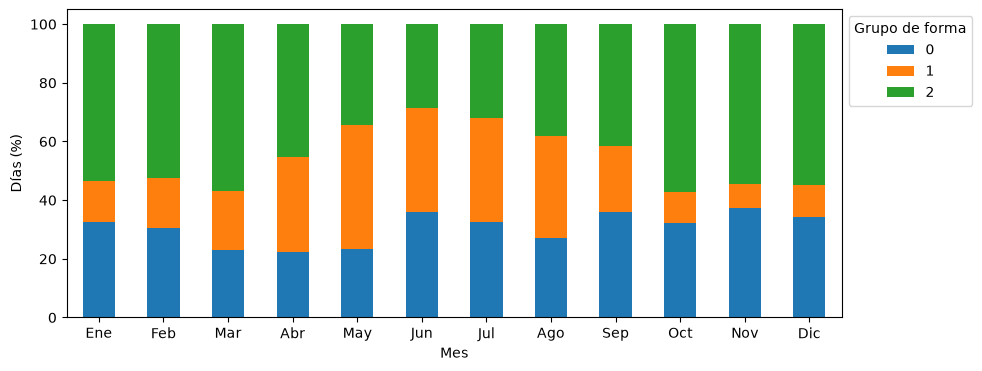

,temp_media,rocio_medio,presion_media,iws_mediana,pct_viento_nw
grupo_forma,,,,,
0,13.8,0.6,1016.8,6.5,37.5
1,21.1,9.8,1011.2,5.6,12.5
2,8.7,-2.6,1019.5,4.5,25.0


In [7]:
dias_forma["mes"] = pd.to_datetime(dias_forma.index).month

forma_por_mes = (
    pd.crosstab(dias_forma["mes"], dias_forma["grupo_forma"], normalize="index")
    .mul(100)
    .rename(index=dict(enumerate(MESES, start=1)))
)
ax = forma_por_mes.plot.bar(stacked=True, figsize=(10, 4), rot=0)
ax.set(xlabel="Mes", ylabel="Días (%)")
ax.legend(title="Grupo de forma", bbox_to_anchor=(1, 1))
plt.show()

meteo_diaria = datos_analisis.groupby("dia").agg(
    temp_media=("TEMP", "mean"),
    rocio_medio=("DEWP", "mean"),
    presion_media=("PRES", "mean"),
    iws_mediana=("Iws", "median"),
    pct_viento_nw=("cbwd", lambda s: 100 * s.eq("NW").mean()),
)
display(
    meteo_diaria.join(dias_forma[["grupo_forma"]], how="inner")
    .groupby("grupo_forma").median().round(1)
)

La forma del día cambia mucho con la estación:

- La **acumulación vespertina** (grupo 2) es la forma mayoritaria de octubre a marzo, con más de la mitad de los días, y baja a menos de un tercio en junio.
- El **pico de mañana** (grupo 1) es frecuente de abril a agosto, entre un 32 % y un 42 % de los días, y raro de octubre a diciembre, con alrededor de un 10 %.
- La **limpieza diurna** (grupo 0) aparece todo el año, entre un 22 % y un 37 % de los días.

La meteorología es coherente con esto. Los días de pico de mañana son más cálidos (mediana de 21,1 °C), más húmedos (punto de rocío de 9,8 °C), con presión baja y solo un 12,5 % de horas con viento del noroeste. Los de acumulación vespertina son fríos (8,7 °C), con presión alta y el viento acumulado más bajo. Los de limpieza diurna tienen la mayor proporción de viento del noroeste (37,5 %) y el `Iws` más alto, compatible con un viento que dispersa la contaminación durante el día. Son asociaciones descriptivas, no efectos causales.

## 3. ¿Son distintos los días que se quedan fuera?

El agrupamiento solo usa días con las 24 lecturas. Si los días incompletos tuvieran concentraciones sistemáticamente distintas, los porcentajes por mes estarían sesgados. Comparamos, para cada mes, la mediana de la media diaria de PM2.5 de los días completos con la de los incompletos (calculada con las horas disponibles).

In [8]:
resumen_dias = pd.DataFrame({
    "media_pm25": pm25_por_dia.mean(axis=1),
    "horas_observadas": pm25_por_dia.notna().sum(axis=1),
})
resumen_dias["tipo"] = np.where(resumen_dias["horas_observadas"].eq(24), "Completo", "Incompleto")
resumen_dias["mes"] = pd.to_datetime(resumen_dias.index).month
con_datos = resumen_dias.loc[resumen_dias["horas_observadas"] > 0]

print(f"Días incompletos: {resumen_dias['tipo'].eq('Incompleto').sum()} "
      f"(sin ninguna lectura: {resumen_dias['horas_observadas'].eq(0).sum()})")

comparacion_tipo = (
    con_datos.groupby(["mes", "tipo"])["media_pm25"]
    .agg(["size", "median"])
    .unstack("tipo")
)
comparacion_tipo.columns = [f"{estad}_{tipo}" for estad, tipo in comparacion_tipo.columns]
comparacion_tipo["diferencia_mediana"] = (
    comparacion_tipo["median_Incompleto"] - comparacion_tipo["median_Completo"]
)
display(comparacion_tipo.rename(index=dict(enumerate(MESES, start=1))).round(1))

display(con_datos.groupby("tipo")["media_pm25"].describe().round(1))

Días incompletos: 254 (sin ninguna lectura: 36)


,size_Completo,size_Incompleto,median_Completo,median_Incompleto,diferencia_mediana
mes,,,,,
Ene,135,13,71.7,118.4,46.7
Feb,135,6,94.5,162.3,67.8
Mar,130,22,69.9,96.8,26.8
Abr,121,28,74.5,65.3,-9.1
May,137,17,71.0,89.0,17.9
Jun,122,26,88.8,82.6,-6.2
Jul,138,16,91.1,60.1,-31.0
Ago,118,30,71.7,100.6,28.9
Sep,128,15,75.1,55.5,-19.6


,count,mean,std,min,25%,50%,75%,max
tipo,,,,,,,,
Completo,1571.0,98.7,76.9,3.0,42.5,78.4,132.9,493.9
Incompleto,218.0,98.3,82.3,10.3,38.1,84.0,122.8,552.5


De los 1.825 días, **254 están incompletos** (36 sin ninguna lectura). En conjunto no hay un sesgo apreciable: la mediana de la media diaria es de **78,4 µg/m³** en los días completos y de **84,0** en los incompletos, y las medias son casi iguales (98,7 frente a 98,3).

Por meses las diferencias son mayores, pero cada mes tiene entre 6 y 30 días incompletos, así que las medianas son poco estables. Lo más destacable es que en **enero y febrero** los días incompletos tienen concentraciones más altas (+47 y +68 µg/m³), y también en agosto, el mes con más días incompletos (+29). En esos meses, los porcentajes calculados solo con días completos podrían infravalorar un poco los días de nivel alto.

## 4. Estimación con la meteorología de la misma hora

Esta regresión responde a *cuánto PM2.5 corresponde a unas condiciones meteorológicas dadas*, usando la meteorología de esa misma hora. **No es un pronóstico**: en la práctica esas variables no se conocen de antemano, así que su MAE no es comparable con el de la sección 5.

Comparamos tres especificaciones entrenadas con 2010–2013 y evaluadas en 2014:

- **Calendario**: hora y mes.
- **Meteorología (Iws lineal)**: la especificación original.
- **Meteorología (log Iws × viento)**: `Iws` es el viento acumulado desde el último cambio de dirección, con una cola larga. Usamos `log1p(Iws)` y dejamos que su efecto cambie según la dirección del viento.

Guardamos cada modelo y sus predicciones por nombre para que el diagnóstico posterior no dependa del orden de un bucle.

In [9]:
observadas = datos_analisis.loc[datos_analisis["pm2.5"].notna()].copy()
observadas["log_iws"] = np.log1p(observadas["Iws"])
for direccion in ["NE", "NW", "SE", "cv"]:
    observadas[f"log_iws_{direccion}"] = observadas["log_iws"] * observadas["cbwd"].eq(direccion)

entreno = observadas.loc[observadas["year"] < 2014]
prueba = observadas.loc[observadas["year"] == 2014]

especificaciones = {
    "Calendario": (["hour", "month"], []),
    "Meteorología (Iws lineal)": (
        ["hour", "month", "cbwd"], ["TEMP", "DEWP", "PRES", "Iws"],
    ),
    "Meteorología (log Iws × viento)": (
        ["hour", "month", "cbwd"],
        ["TEMP", "DEWP", "PRES", "log_iws_NE", "log_iws_NW", "log_iws_SE", "log_iws_cv"],
    ),
}

modelos_regresion = {}
predicciones_regresion = {}

for nombre, (categoricas, numericas) in especificaciones.items():
    codificador = ColumnTransformer([
        ("categoricas", OneHotEncoder(drop="first", handle_unknown="ignore"), categoricas),
        ("numericas", "passthrough", numericas),
    ])
    modelo = make_pipeline(codificador, LinearRegression())
    modelo.fit(entreno[categoricas + numericas], entreno["pm2.5"])

    modelos_regresion[nombre] = modelo
    predicciones_regresion[nombre] = pd.Series(
        modelo.predict(prueba[categoricas + numericas]).clip(min=0), index=prueba.index
    )

display(pd.Series(
    {n: mean_absolute_error(prueba["pm2.5"], p) for n, p in predicciones_regresion.items()},
    name="MAE (µg/m³)",
).round(2).to_frame())

,MAE (µg/m³)
Calendario,68.06
Meteorología (Iws lineal),51.41
Meteorología (log Iws × viento),51.42


In [10]:
umbral_alto = entreno["pm2.5"].quantile(0.95)
print(f"Umbral de PM2.5 alto (percentil 95 de 2010–2013): {umbral_alto:.0f} µg/m³")

nivel_observado = prueba["pm2.5"].ge(umbral_alto).map({True: "PM2.5 alto", False: "Resto de horas"})

diagnostico = []
for nombre, prediccion in predicciones_regresion.items():
    error = prediccion - prueba["pm2.5"]
    resumen = pd.DataFrame({"observado": prueba["pm2.5"], "estimado": prediccion, "error": error})
    resumen = resumen.groupby(nivel_observado).agg(
        horas=("observado", "size"),
        observado_medio=("observado", "mean"),
        estimado_medio=("estimado", "mean"),
        MAE=("error", lambda e: e.abs().mean()),
        error_medio=("error", "mean"),
    )
    diagnostico.append(resumen.assign(modelo=nombre).set_index("modelo", append=True))

display(pd.concat(diagnostico).swaplevel().sort_index().round(2))

Umbral de PM2.5 alto (percentil 95 de 2010–2013): 282 µg/m³


horas  observado_medio  \
modelo                          pm2.5                                    
Calendario                      PM2.5 alto        516           366.33   
                                Resto de horas   8145            80.72   
Meteorología (Iws lineal)       PM2.5 alto        516           366.33   
                                Resto de horas   8145            80.72   
Meteorología (log Iws × viento) PM2.5 alto        516           366.33   
                                Resto de horas   8145            80.72   

                                                estimado_medio     MAE  \
modelo                          pm2.5                                    
Calendario                      PM2.5 alto              112.00  254.33   
                                Resto de horas           97.82   56.26   
Meteorología (Iws lineal)       PM2.5 alto              170.21  196.12   
                                Resto de horas           95.30   42.24   
Meteorología (log Iws × viento) PM2.5 alto              173.29  193.05   
                                Resto de horas           96.61   42.45   

                                                error_medio  
modelo                          pm2.5                        
Calendario                      PM2.5 alto          -254.33  
                                Resto de horas        17.10  
Meteorología (Iws lineal)       PM2.5 alto          -196.12  
                                Resto de horas        14.58  
Meteorología (log Iws × viento) PM2.5 alto          -193.05  
                                Resto de horas        15.89

Pasar `Iws` a escala logarítmica e interactuarlo con la dirección del viento **no mejora la regresión**: el MAE es de 51,42 frente a 51,41 µg/m³. En las horas de PM2.5 alto el MAE baja muy poco (de 196,1 a 193,1 µg/m³) y el modelo sigue estimando unos 173 µg/m³ cuando la media observada es de 366.

La subestimación de los picos no se debe a la forma funcional de `Iws`. Un modelo lineal con la meteorología de una sola hora no recoge la acumulación de contaminación a lo largo de varias horas o días, que es lo que produce los episodios más altos.

## 5. Pronóstico a una hora

A partir de aquí cada método solo usa información disponible hasta la hora anterior. Trabajamos sobre la cuadrícula horaria completa, conservando los huecos:

- **Ajuste**: 2010–2012, para el diagnóstico (ACF/PACF) y el ajuste de los candidatos.
- **Validación**: 2013, para elegir el modelo.
- **Prueba**: 2014, solo para la evaluación final, reajustando con 2010–2013.

La referencia es la **persistencia**: repetir la última medición disponible.

In [11]:
serie_horaria = datos_analisis.set_index("fecha_hora").asfreq("h")
pm = serie_horaria["pm2.5"]
log_pm = np.log1p(pm)

inicio_validacion = pd.Timestamp("2013-01-01", tz=ZONA)
inicio_prueba = pd.Timestamp("2014-01-01", tz=ZONA)

tramo_ajuste = pm.index < inicio_validacion
tramo_validacion = (pm.index >= inicio_validacion) & (pm.index < inicio_prueba)
tramo_entreno = pm.index < inicio_prueba
tramo_prueba = pm.index >= inicio_prueba

persistencia = pm.ffill().shift(1)

### 5.1 Diagnóstico con 2010–2012

En el análisis original la ACF y la PACF incluían 2013, que después se usaba para validar. Aquí solo usamos el tramo de ajuste. La PACF necesita una serie sin huecos, así que se calcula sobre el tramo continuo más largo.

Tramo continuo más largo: 1330 horas (2011-06-06 a 2011-07-31)


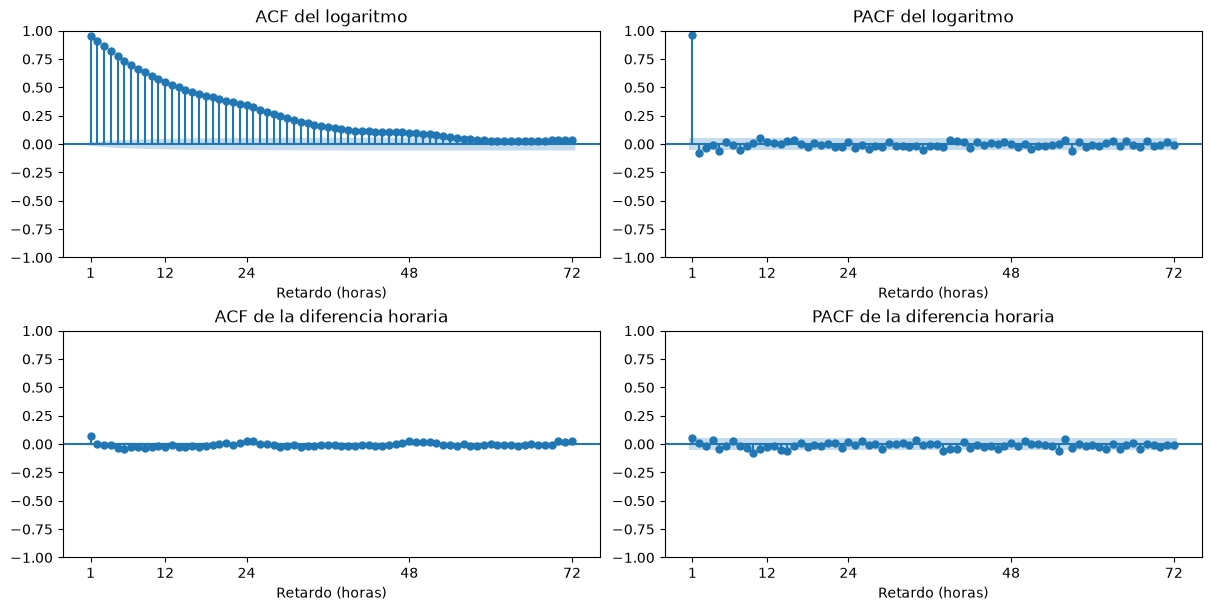

In [12]:
log_ajuste = log_pm.loc[tramo_ajuste]

observado = log_ajuste.notna()
tramos = observado.ne(observado.shift()).cumsum()
tramo_mayor = tramos[observado].value_counts().idxmax()
log_continuo = log_ajuste.loc[tramos.eq(tramo_mayor)]
print(f"Tramo continuo más largo: {len(log_continuo)} horas "
      f"({log_continuo.index[0]:%Y-%m-%d} a {log_continuo.index[-1]:%Y-%m-%d})")

fig, axes = plt.subplots(2, 2, figsize=(12, 6), layout="constrained")
plot_acf(log_ajuste, lags=72, missing="conservative", zero=False, ax=axes[0, 0], title="ACF del logaritmo")
plot_pacf(log_continuo, lags=72, method="ywm", zero=False, ax=axes[0, 1], title="PACF del logaritmo")
plot_acf(log_ajuste.diff(), lags=72, missing="conservative", zero=False, ax=axes[1, 0],
         title="ACF de la diferencia horaria")
plot_pacf(log_continuo.diff().iloc[1:], lags=72, method="ywm", zero=False, ax=axes[1, 1],
          title="PACF de la diferencia horaria")
for ax in axes.flat:
    ax.set(xlabel="Retardo (horas)", xticks=[1, 12, 24, 48, 72])
plt.show()

Calculadas solo con 2010–2012, la ACF y la PACF muestran lo mismo que en el análisis original: la ACF del logaritmo empieza en torno a 0,96 y decae despacio, y en la PACF domina el retardo de una hora. Tras diferenciar, solo queda una autocorrelación pequeña en el primer retardo (≈ 0,07) y **no se aprecia ningún pico a las 24 horas**. Por tanto, la fuga de información del análisis original no cambiaba el diagnóstico. También anticipa que los términos de ciclo diario aportarán poco al pronóstico a una hora.

### 5.2 Variables externas

Para incorporar el ciclo diario sin un modelo estacional completo usamos **términos de Fourier**: senos y cosenos de la hora del día con periodos de 24, 12 y 8 horas. Son deterministas, así que se conocen de antemano.

Para la meteorología usamos los valores de la **hora anterior** (temperatura, punto de rocío, presión, `log1p(Iws)` y dirección del viento), que sí estarían disponibles al pronosticar.

In [13]:
hora_del_dia = serie_horaria.index.hour.to_numpy()
fourier = pd.DataFrame(index=serie_horaria.index)
for armonico in (1, 2, 3):
    angulo = 2 * np.pi * armonico * hora_del_dia / 24
    fourier[f"sen_{armonico}"] = np.sin(angulo)
    fourier[f"cos_{armonico}"] = np.cos(angulo)

meteo_actual = pd.concat([
    serie_horaria[["TEMP", "DEWP", "PRES"]],
    np.log1p(serie_horaria["Iws"]).rename("log_iws"),
    pd.get_dummies(serie_horaria["cbwd"], prefix="viento", drop_first=True, dtype=float),
], axis=1)
meteo_anterior = meteo_actual.shift(1).bfill().add_suffix("_t-1")

print(f"Valores ausentes en las variables externas: {meteo_anterior.isna().sum().sum()}")
exog_fourier = fourier
exog_fourier_meteo = pd.concat([fourier, meteo_anterior], axis=1)

Valores ausentes en las variables externas: 0


### 5.3 Regresión de pronóstico

Una alternativa sencilla al ARIMA: una regresión lineal que estima el **cambio** de `log1p(PM2.5)` respecto a la última lectura disponible. Si todos los coeficientes fueran cero, el pronóstico sería la persistencia, así que la regresión solo tiene que aprender cuándo conviene apartarse de ella.

No incluimos el nivel de la última lectura como variable. Con él, el modelo aprendería un coeficiente algo menor que 1 y tiraría siempre de los pronósticos hacia la media, que es justo lo que perjudica a los modelos AR estacionarios en los picos. Las variables son:

- el último cambio observado y la diferencia entre la lectura de hace 24 horas y la última;
- las horas transcurridas desde la última lectura;
- la hora del día y el mes;
- la meteorología de la hora anterior y su cambio respecto a la hora previa.

Los retardos se calculan con la última lectura disponible para poder pronosticar todas las horas observadas, igual que la persistencia y el ARIMA.

In [14]:
log_relleno = log_pm.ffill()
ultima_lectura = log_relleno.shift(1)
horas_sin_lectura = (
    pm.notna().cumsum().groupby(pm.notna().cumsum()).cumcount().shift(1).fillna(0)
)

variables_pronostico = pd.concat([
    (log_relleno.shift(1) - log_relleno.shift(2)).rename("ultimo_cambio"),
    (log_relleno.shift(24) - log_relleno.shift(1)).rename("lectura_t-24_menos_t-1"),
    np.log1p(horas_sin_lectura).rename("log_horas_sin_lectura"),
    pd.get_dummies(serie_horaria["hour"], prefix="h", drop_first=True, dtype=float),
    pd.get_dummies(serie_horaria["month"], prefix="m", drop_first=True, dtype=float),
    meteo_anterior,
    meteo_actual.diff().shift(1).add_suffix("_cambio_t-1"),
], axis=1)


def pronostico_regresion(tramo_fit, tramo_pred):
    """Ajusta con las horas observadas de tramo_fit y pronostica tramo_pred."""
    validas = variables_pronostico.notna().all(axis=1)
    filas_fit = tramo_fit & validas.to_numpy() & pm.notna().to_numpy()
    cambio = log_pm - ultima_lectura
    modelo = LinearRegression().fit(variables_pronostico.loc[filas_fit], cambio.loc[filas_fit])
    filas_pred = variables_pronostico.loc[tramo_pred]
    pred_log = ultima_lectura.loc[tramo_pred] + modelo.predict(filas_pred)
    return np.expm1(pred_log).clip(lower=0)

### 5.4 Candidatos y validación en 2013

Todos los modelos de la familia ARIMA se ajustan sobre `log1p(PM2.5)` y el pronóstico se devuelve a µg/m³ con `expm1`. En escala logarítmica, `expm1` del pronóstico se aproxima a la mediana condicional, que es lo adecuado cuando se evalúa con el MAE.

- **AR(1)** y **AR(2)** con constante, y **ARIMA(0,1,1)**: los del análisis original.
- **ARIMA(0,1,1) + Fourier**: añade el ciclo diario.
- **ARIMA(0,1,1) + Fourier + meteorología t-1**.
- **SARIMA(1,0,1)(1,0,0)₂₄**: un componente estacional explícito de 24 horas. Es el más lento de ajustar (unos minutos).
- **Regresión de pronóstico** (sección 5.3).

In [15]:
CANDIDATOS_ARIMA = {
    "AR(1)": dict(order=(1, 0, 0), trend="c"),
    "AR(2)": dict(order=(2, 0, 0), trend="c"),
    "ARIMA(0,1,1)": dict(order=(0, 1, 1), trend="n"),
    "ARIMA(0,1,1) + Fourier": dict(order=(0, 1, 1), trend="n", exog=exog_fourier),
    "ARIMA(0,1,1) + Fourier + meteo t-1": dict(order=(0, 1, 1), trend="n", exog=exog_fourier_meteo),
    "SARIMA(1,0,1)(1,0,0)24": dict(order=(1, 0, 1), seasonal_order=(1, 0, 0, 24), trend="c"),
}


def pronostico_arima(especificacion, tramo_fit, tramo_pred):
    """Ajusta con tramo_fit y devuelve el pronóstico a una hora en tramo_pred (µg/m³)."""
    especificacion = dict(especificacion)
    exog = especificacion.pop("exog", None)
    ajuste = SARIMAX(
        log_pm.loc[tramo_fit],
        exog=None if exog is None else exog.loc[tramo_fit],
        **especificacion,
    ).fit(disp=False)
    extendido = ajuste.extend(
        log_pm.loc[tramo_pred],
        exog=None if exog is None else exog.loc[tramo_pred],
    )
    pred_log = extendido.get_prediction(information_set="predicted").predicted_mean
    return np.expm1(pred_log).clip(lower=0), ajuste


pronosticos_validacion = pd.DataFrame({"Persistencia": persistencia.loc[tramo_validacion]})
ajustes_validacion = {}

for nombre, especificacion in CANDIDATOS_ARIMA.items():
    pronosticos_validacion[nombre], ajustes_validacion[nombre] = pronostico_arima(
        especificacion, tramo_ajuste, tramo_validacion
    )

pronosticos_validacion["Regresión de pronóstico"] = pronostico_regresion(tramo_ajuste, tramo_validacion)

pm_validacion = pm.loc[tramo_validacion]
horas_validas = pm_validacion.notna()
mae_validacion = (
    pronosticos_validacion.loc[horas_validas]
    .sub(pm_validacion.loc[horas_validas], axis=0)
    .abs().mean().sort_values()
)
mae_validacion = mae_validacion.to_frame("MAE (µg/m³)").assign(
    mejora_vs_persistencia_pct=lambda t: 100 * (1 - t["MAE (µg/m³)"] / t.loc["Persistencia", "MAE (µg/m³)"])
)
display(mae_validacion.round(2))

,MAE (µg/m³),mejora_vs_persistencia_pct
"ARIMA(0,1,1)",13.04,1.27
"ARIMA(0,1,1) + Fourier",13.12,0.65
"ARIMA(0,1,1) + Fourier + meteo t-1",13.18,0.21
Persistencia,13.21,0.00
Regresión de pronóstico,13.28,-0.58
"SARIMA(1,0,1)(1,0,0)24",13.90,-5.22
AR(2),13.91,-5.31
AR(1),14.03,-6.26


### 5.5 ¿Por qué el ARIMA(0,1,1) se parece tanto a la persistencia?

El pronóstico de un ARIMA(0,1,1) sin constante es la última lectura más una fracción θ del último error de pronóstico:

ŷₜ₊₁ = yₜ + θ · (yₜ − ŷₜ)

Es la misma fórmula que el suavizado exponencial simple con α = 1 + θ. Con θ = 0 el modelo es exactamente la persistencia, así que el valor estimado de θ indica cuánto se aparta de ella.

In [16]:
theta = ajustes_validacion["ARIMA(0,1,1)"].params["ma.L1"]
print(f"θ = {theta:.3f}  (α equivalente = 1 + θ = {1 + theta:.3f})")

θ = 0.067  (α equivalente = 1 + θ = 1.067)


Resultados en la validación de 2013:

- **ARIMA(0,1,1)** sigue siendo el mejor modelo: MAE de **13,04 µg/m³**, un 1,3 % menos que la persistencia (13,21).
- **Añadir el ciclo diario o la meteorología no ayuda**: el MAE sube a 13,12 con Fourier y a 13,18 con Fourier y meteorología.
- La **regresión de pronóstico** (13,28) queda prácticamente empatada con la persistencia.
- Los modelos **estacionarios** (AR(1), AR(2) y SARIMA, cuyo coeficiente AR es de 0,95) son los peores, con un MAE de entre 13,90 y 14,03. Tiran de cada pronóstico hacia la media de la serie, lo que perjudica sobre todo en los episodios largos de concentración alta o baja.

El coeficiente estimado es θ = 0,067: el ARIMA(0,1,1) pronostica la última lectura más un 6,7 % del último error, es decir, casi la persistencia. Por eso la diferencia entre ambos es tan pequeña. La hora siguiente depende sobre todo de la hora actual, y el resto de información aporta muy poco a una hora vista.

### 5.6 Evaluación final en 2014

Reajustamos con 2010–2013 el mejor modelo de validación de cada tipo y lo comparamos con la persistencia y con el ARIMA(0,1,1) original. Medimos el MAE global y el MAE en las horas con PM2.5 igual o superior al percentil 95 de 2010–2013.

In [17]:
mejor_arima = (
    mae_validacion.drop(index=["Persistencia", "Regresión de pronóstico"])["MAE (µg/m³)"].idxmin()
)
print(f"Mejor modelo de la familia ARIMA en validación: {mejor_arima}")

modelos_finales = dict.fromkeys(["ARIMA(0,1,1)", mejor_arima])
pronosticos_2014 = pd.DataFrame({"Persistencia": persistencia.loc[tramo_prueba]})
for nombre in modelos_finales:
    pronosticos_2014[nombre], _ = pronostico_arima(CANDIDATOS_ARIMA[nombre], tramo_entreno, tramo_prueba)
pronosticos_2014["Regresión de pronóstico"] = pronostico_regresion(tramo_entreno, tramo_prueba)

pm_prueba = pm.loc[tramo_prueba]
umbral_alto_2014 = pm.loc[tramo_entreno].quantile(0.95)
errores_2014 = pronosticos_2014.sub(pm_prueba, axis=0).abs().loc[pm_prueba.notna()]
horas_altas = pm_prueba.loc[pm_prueba.notna()].ge(umbral_alto_2014)

comparacion_final = pd.DataFrame({
    "MAE global": errores_2014.mean(),
    "MAE en PM2.5 alto": errores_2014.loc[horas_altas].mean(),
})
comparacion_final["mejora_global_pct"] = 100 * (
    1 - comparacion_final["MAE global"] / comparacion_final.loc["Persistencia", "MAE global"]
)
print(f"Horas evaluadas: {len(errores_2014):,} · con PM2.5 ≥ {umbral_alto_2014:.0f}: {horas_altas.sum()}")
display(comparacion_final.round(2))

Mejor modelo de la familia ARIMA en validación: ARIMA(0,1,1)


Horas evaluadas: 8,661 · con PM2.5 ≥ 282: 516


,MAE global,MAE en PM2.5 alto,mejora_global_pct
Persistencia,11.96,25.00,0.00
"ARIMA(0,1,1)",11.78,24.65,1.46
Regresión de pronóstico,12.10,28.74,-1.15


## Conclusiones

1. **Hay tres formas típicas de día, y no dependen del nivel.** Al estandarizar los días aparecen la *limpieza diurna*, el *pico de mañana* y la *acumulación vespertina*. Forma y nivel son casi independientes (ARI = 0,017). La acumulación vespertina domina de octubre a marzo y el pico de mañana es propio de los meses cálidos, cada uno asociado a condiciones meteorológicas distintas.
2. **Los días descartados no sesgan el conjunto**, aunque en enero, febrero y agosto los días incompletos tienden a tener concentraciones más altas.
3. **Transformar `Iws` no mejora la estimación con la meteorología de la misma hora**, y los picos siguen muy subestimados. Esta tarea es distinta del pronóstico y sus errores no son comparables.
4. **En el pronóstico a una hora, nada supera claramente a la persistencia.** En 2014 el ARIMA(0,1,1) obtiene un MAE de 11,78 µg/m³ frente a 11,96 de la persistencia (un 1,5 % menos) y de 24,65 frente a 25,00 en las horas de PM2.5 alto, una mejora práctica muy pequeña. La regresión de pronóstico queda cerca de la persistencia en el conjunto de horas (12,10) pero es peor en los picos (28,74). Añadir el ciclo diario, un componente estacional o la meteorología de la hora anterior no ayuda, y los modelos que revierten a la media empeoran.

**Siguientes pasos.** Un horizonte más largo (6, 12 o 24 horas) es donde la persistencia deja de funcionar, y ahí la meteorología y el ciclo diario deberían aportar más. También se puede probar un modelo no lineal (por ejemplo, *gradient boosting*) que recoja la acumulación de varias horas para estimar mejor los episodios altos.